In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 0)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
source_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_1.csv'
target_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor.csv'
append_csv(source_file, target_file)

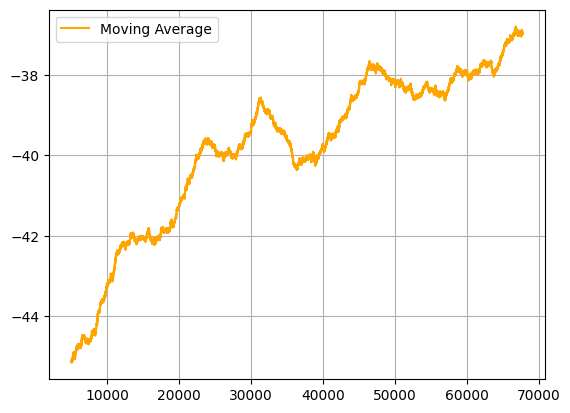

In [5]:


monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_2.csv"
# MONITOR_2 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 5000
moving_average = monitor_data['r'].rolling(window=window_size).mean()

fig, ax = plt.subplots()
ax.plot(moving_average, label='Moving Average', color='orange')
ax.legend()
ax.grid()

plt.show()

In [6]:
print(len(moving_average))

67731


I changed the calculation of latency. In order to do so, I slightly changed the buffer, which becomes a stack to capture the waiting time. 
The model is trained overnight, with 653000 (5 hours) + 1200000 (9 hours) timesteps.

The entropy loss of the policy goes from -22.5 to -13.2 during this 14 hours. The entropy loss evaluates the difference between the old and the new policy. It should be close to 0 when the policy converges. However, it is far from there. 
